# Make Circles

Start of by some simple widely supported device agnostic code 

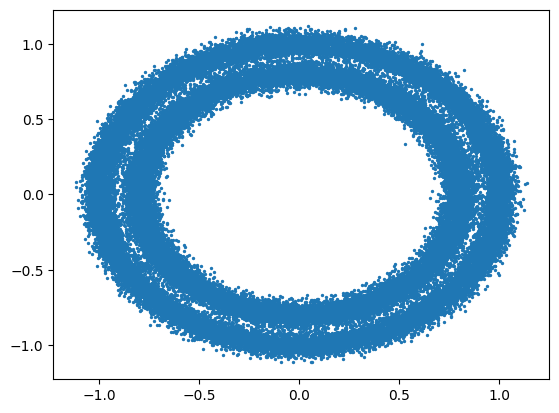

In [1]:
from sklearn.datasets import make_circles
import torch
from sklearn.model_selection import train_test_split
import matplotlib.pylab as plt
import numpy as np
from torch import nn


### Device agnostic code (GPU is not required on a dataset this small)
def get_device(force_cpu=False):
    if force_cpu:
        return torch.device("cpu")
    if torch.cuda.is_available(): ## NVIDIA
        return torch.device("cuda")
    if torch.backends.mps.is_available(): ## Apple Silicon
        return torch.device("mps")
    try:
        import torch_directml ## AMD
        if torch_directml.device_count() > 0:
            return torch_directml.device()
    except ImportError:
        pass
    return torch.device("cpu")


device = get_device(force_cpu=True)

### Reproducibility
np.random.seed(42)
torch.manual_seed(42)


### Making the data (with seed 42 for reproducibility)
X, y = make_circles(n_samples=50000, shuffle=True, noise=0.04, random_state=42)

### Transforming to Tensors (Numpy -> Tensors)
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)


### Ploting the data
plt.scatter(X[:, 0], X[:, 1], s=2)


### Training and Testing split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, shuffle=True)

## Defining the core models

In [ ]:
### Reserch loop
def ReserchLoop(n_samples, ):
    pass

class BaselineMLP(nn.Module): ## Standard Neural Network using (x, y)
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=16)
        self.activation1 = nn.ReLU()

        self.layer2 = nn.Linear(in_features=16, out_features=16)
        self.activation2 = nn.ReLU()

        self.outputLayer = nn.Linear(in_features=16, out_features=1)
    def forward(self, x: torch.tensor): 
        x = self.layer1(x)
        x = self.activation1(x)

        x = self.layer2(x)
        x = self.activation2(x)

        x = self.outputLayer(x)
        return x

class RadialMLP(nn.Module): ## Geometry-aware network using the radius
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=1, out_features=16)
        self.activation1 = nn.ReLU()

        self.layer2 = nn.Linear(in_features=16, out_features=16)
        self.activation2 = nn.ReLU()

        self.outputLayer = nn.Linear(in_features=16, out_features=1)
    def forward(self, X: torch.tensor):
        radius = torch.sqrt(X[:, 0]**2 + X[:, 1]**2)
        radius = radius.unsqueeze(dim=1)
        
        x = self.layer1(radius)
        x = self.activation1(x)

        x = self.layer2(x)
        x = self.activation1(x)

        x = self.outputLayer(x)
        return x 

class RadialLogisticRegression(nn.Module): ## Simple linear classifier using radius 
    def __init__(self):
        super().__init__()
        
        # Single Linear Layer
        self.layer = nn.Linear(1, 1)

    def forward(self, x: torch.tensor):
        radius = torch.sqrt(X[:, 0]**2 + X[:, 1]**2)
        radius = radius.unsqueeze(dim=1)

        x = self.layer(radius)
        return x


def Sigmoid(logits: torch.tensor): 
    return (torch.sigmoid(logits) >= 0.5)



Epoch: 1 | Train Accuracy: 58.74% | Test Accuracy: 84.25% | Train Loss: 0.6773 | Test Loss: 0.6408
Epoch: 2 | Train Accuracy: 91.20% | Test Accuracy: 96.58% | Train Loss: 0.5124 | Test Loss: 0.3481
Epoch: 3 | Train Accuracy: 98.65% | Test Accuracy: 99.10% | Train Loss: 0.2187 | Test Loss: 0.1365
Epoch: 4 | Train Accuracy: 99.20% | Test Accuracy: 99.21% | Train Loss: 0.1042 | Test Loss: 0.0787
Epoch: 5 | Train Accuracy: 99.29% | Test Accuracy: 99.20% | Train Loss: 0.0665 | Test Loss: 0.0556
Epoch: 6 | Train Accuracy: 99.31% | Test Accuracy: 99.25% | Train Loss: 0.0495 | Test Loss: 0.0434
Epoch: 7 | Train Accuracy: 99.30% | Test Accuracy: 99.17% | Train Loss: 0.0400 | Test Loss: 0.0375
Epoch: 8 | Train Accuracy: 99.33% | Test Accuracy: 99.29% | Train Loss: 0.0342 | Test Loss: 0.0328
Epoch: 9 | Train Accuracy: 99.33% | Test Accuracy: 99.20% | Train Loss: 0.0304 | Test Loss: 0.0307
Epoch: 10 | Train Accuracy: 99.35% | Test Accuracy: 99.28% | Train Loss: 0.0276 | Test Loss: 0.0277
Epoch: 11

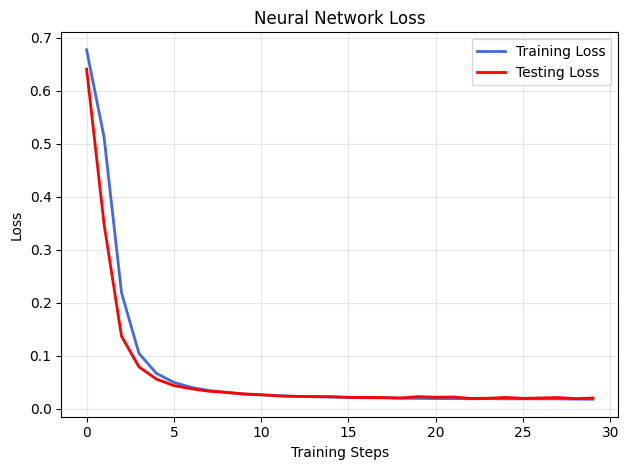

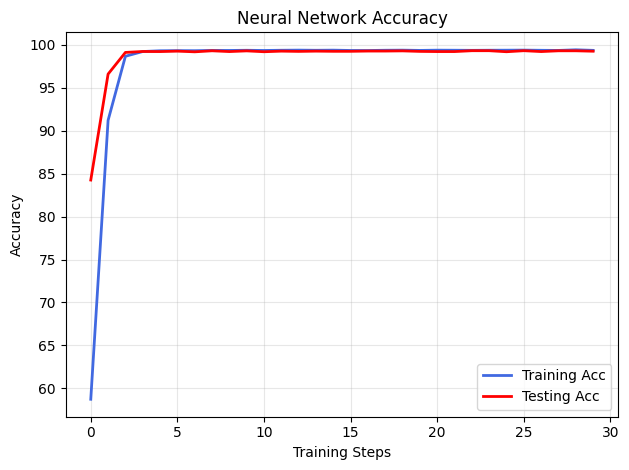

In [4]:
### Transfering the training and testing data to the GPU if required
X_train = X_train.to(device)
y_train = y_train.to(device)

X_test= X_test.to(device)
y_test = y_test.to(device)


### Init Model
model0 = BaselineMLP().to(device)


### Hyperparamaters loop
epochs = 30
lr = 0.001
batch = 128


### Init Optim and loss
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model0.parameters(), lr=lr)


### Empty Variables 
avg_loss_train = []
avg_loss_test = []
avg_test_accuracy = []
avg_train_accuracy = []



### Training/Testing loop
for epoch in range(epochs):
    model0.train()

    loss_train = []
    loss_test = []
    correct_predictions = 0

    ### Shuffle the training data (Mini-Batch)
    indecies = torch.randperm(len(X_train))
    X_train = X_train[indecies]
    y_train = y_train[indecies]

    ## Training Loop (Mini-Batch)
    for start in range(0, len(X_train), batch):
        end = start + batch
        X_batch = X_train[start:end]
        y_batch = y_train[start:end]

        train_logits = model0(X_batch)

        loss = loss_fn(train_logits, y_batch.unsqueeze(dim=1))

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        
        ### Accuracy
        predicted_class = Sigmoid(train_logits)
        correct_predictions += (predicted_class == y_batch.unsqueeze(1)).sum().item()

        ### Store training loss
        loss_train.append(loss.item())

    ### Average training accuracy and loss (per epoch)
    train_accuracy = correct_predictions / len(X_train) * 100
    avg_train_accuracy.append(train_accuracy)

    train_loss = sum(loss_train) / len(loss_train)
    avg_loss_train.append(train_loss)

    ### Evaluation
    model0.eval()

    with torch.no_grad():
        test_logits = model0(X_test)
        test_preds = Sigmoid(test_logits)

        ### Test accuracy
        test_accuracy = (test_preds == y_test.unsqueeze(1)).float().mean() * 100

        avg_test_accuracy.append(test_accuracy.item())

        ### Test loss
        test_loss = loss_fn(test_logits, y_test.unsqueeze(1))
        avg_loss_test.append(test_loss.item())

    ### Print results for this epoch
    print(
        f"Epoch: {epoch + 1} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy.item():.2f}% | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss.item():.4f}"
    )





### Loss graph
plt.figure()

plt.plot(avg_loss_train, color="royalblue", linewidth=2, label="Training Loss")
plt.plot(avg_loss_test, color="red", linewidth=2, label="Testing Loss")

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Neural Network Loss")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Acc graph
plt.figure()

plt.plot(avg_train_accuracy, color="royalblue", linewidth=2, label="Training Acc")
plt.plot(avg_test_accuracy, color="red", linewidth=2, label="Testing Acc")

plt.xlabel("Training Steps")
plt.ylabel("Accuracy")
plt.title("Neural Network Accuracy")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

